# <b><div class="alert alert-block alert-info" style='padding:15px;background-color:#37006f;color:white;border-radius:40px;font-size:110%;text-align: center;margin: auto;'>Fine-tune a pretrained latent diffusion model</div></b>

Instead of training a diffusion model from scratch, this notebook starts from a pretrained **latent diffusion** model (Stable Diffusion 1.5 from the Hugging Face Hub).

## <b><div class="alert alert-block alert-info" style='padding:15px;background-color:#37006f;color:white;border-radius:40px;font-size:110%;text-align: center;margin: auto;'>1 | Setup</div></b>

In [1]:
cd ..

d:\Personal Projects\picasso


d:\Personal Projects\picasso\.venv\lib\site-packages\IPython\core\magics\osm.py:417: UserWarning: This is now an optional IPython functionality, setting dhist requires you to install the `pickleshare` library.
  self.shell.db['dhist'] = compress_dhist(dhist)[-100:]


In [2]:
%pip install -q -U diffusers peft transformers accelerate safetensors
%pip uninstall -y -q torchao

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


## <b><div class="alert alert-block alert-info" style='padding:15px;background-color:#37006f;color:white;border-radius:40px;font-size:110%;text-align: center;margin: auto;'>2 | Download the dataset (Kaggle)</div></b>

Downloads the `art-nouveau` folder of the Hugging Face dataset into `DATASET_DIR`. It is skipped if the folder already has images, and downloads resume if interrupted. Public repos need no token; for a private/gated repo add a Kaggle secret named `HF_TOKEN` (Add-ons -> Secrets).

In [3]:
import os
from pathlib import Path
from huggingface_hub import snapshot_download

HF_DATASET = "StyleGender/StyleGender-Dataset"
HF_PREFIX = "art-nouveau"                                   # folder inside the repo
DATASET_DIR = "datasets"    # images land in DATASET_DIR/HF_PREFIX (= DATA_ROOT below)

token = os.environ.get("HF_TOKEN")
try:
    from kaggle_secrets import UserSecretsClient
    token = UserSecretsClient().get_secret("HF_TOKEN")
except Exception:
    pass                                                    # no secret set / not on Kaggle

target = Path(DATASET_DIR) / HF_PREFIX
n_existing = sum(1 for p in target.rglob("*") if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp", ".bmp"}) if target.exists() else 0
if n_existing:
    print(f"{n_existing} images already in {target} - skipping download")
else:
    snapshot_download(
        HF_DATASET, repo_type="dataset",
        allow_patterns=[f"{HF_PREFIX}/*"],
        local_dir=DATASET_DIR, token=token,
    )
    n = sum(1 for p in target.rglob("*") if p.is_file())
    print(f"Downloaded {n} files -> {target}")

4845 images already in datasets\art-nouveau - skipping download


d:\Personal Projects\picasso\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## <b><div class="alert alert-block alert-info" style='padding:15px;background-color:#37006f;color:white;border-radius:40px;font-size:110%;text-align: center;margin: auto;'>3 | Imports</div></b>

In [4]:
import os, math, random, itertools
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageFile
from tqdm.auto import tqdm

import torch
import torch.nn.functional as F
import torchvision.transforms as transforms
import torchvision.transforms.functional as TF
import torchvision.utils as vutils

from transformers import CLIPTextModel, CLIPTokenizer
from diffusers import (
    AutoencoderKL, DDPMScheduler, DPMSolverMultistepScheduler,
    StableDiffusionPipeline, UNet2DConditionModel,
)
from diffusers.optimization import get_scheduler
from diffusers.training_utils import cast_training_params
from diffusers.utils import convert_state_dict_to_diffusers
from peft import LoraConfig
from peft.utils import get_peft_model_state_dict, set_peft_model_state_dict

ImageFile.LOAD_TRUNCATED_IMAGES = True   # tolerate slightly truncated files
%matplotlib inline

## <b><div class="alert alert-block alert-info" style='padding:15px;background-color:#37006f;color:white;border-radius:40px;font-size:110%;text-align: center;margin: auto;'>4 | Configuration</div></b>

Everything you are likely to change is here.

- **`DEFAULT_CAPTION`** is used for every image. If an image has a text file next to it with the same name (`0001.jpg` -> `0001.txt`), that file's text is used instead. Mention the style you want to learn (here "art nouveau"), and use the same wording in your prompts later.
- **`MAX_STEPS`** counts optimizer steps. Each step sees `BATCH_SIZE x GRAD_ACCUM` images (default 1 x 4 = 4), so 2000 steps is about 8000 images, or ~1.6 passes over a 4.8k-image dataset. For style adaptation, 1500-3000 steps is a sensible range; watch the validation images and stop when they look right.
- **`RANK`** is the LoRA size: higher = more capacity and a bigger file. 8-32 is typical.

In [5]:
# ---------------- model & data ----------------
MODEL_ID = "stable-diffusion-v1-5/stable-diffusion-v1-5"   # mirror of SD 1.5 on the Hub
DATA_ROOT = "./datasets/art-nouveau"   # folder with your images (searched recursively)
OUTPUT_DIR = "./checkpoints/lora_output"
DEFAULT_CAPTION = "an illustration in art nouveau style"

# ---------------- training ----------------
RESOLUTION = 512            # SD 1.5 was trained at 512.
BATCH_SIZE = 1
GRAD_ACCUM = 4              # effective batch size = BATCH_SIZE * GRAD_ACCUM
MAX_STEPS = 2000            # optimizer steps
LEARNING_RATE = 1e-4
LR_SCHEDULER = "cosine"
LR_WARMUP_STEPS = 100
RANK = 16
SNR_GAMMA = 5.0             # min-SNR loss weighting (None to disable); speeds up convergence
MAX_GRAD_NORM = 1.0
RANDOM_FLIP = True
GRADIENT_CHECKPOINTING = True   # saves a lot of GPU memory, ~20% slower
NUM_WORKERS = 2
SEED = 1337

# ---------------- validation / checkpoints ----------------
VALIDATION_PROMPTS = [
    "an illustration in art nouveau style, portrait of a woman with flowing hair",
    "an illustration in art nouveau style, portrait of a man in a suit",
    "an illustration in art nouveau style, a garden with flowers and a peacock",
]
VALIDATION_SEEDS = [11, 22, 33]
VALIDATION_EVERY = 500
CHECKPOINT_EVERY = 500
RESUME_FROM = None          # e.g. "lora_output/training_state.pt" to continue an interrupted run

# ---------------- device ----------------
ALLOW_CPU = True           # only for a quick smoke test; real training needs a GPU
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE == "cpu" and not ALLOW_CPU:
    raise RuntimeError("No GPU found. Switch the notebook to a GPU runtime (e.g. Kaggle: Settings -> Accelerator -> GPU T4).")
WEIGHT_DTYPE = torch.float16 if DEVICE == "cuda" else torch.float32
USE_AMP = DEVICE == "cuda"

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
os.makedirs(OUTPUT_DIR, exist_ok=True)
print("Device:", DEVICE, "| dtype:", WEIGHT_DTYPE)

Device: cpu | dtype: torch.float32


## <b><div class="alert alert-block alert-info" style='padding:15px;background-color:#37006f;color:white;border-radius:40px;font-size:110%;text-align: center;margin: auto;'>5 | Dataset</div></b>

Images are resized so the short side equals `RESOLUTION`, center-cropped, optionally flipped, and normalized to [-1, 1]. Unreadable files are skipped at load time instead of crashing training.

4845 images under ./datasets/art-nouveau
Example caption: an illustration in art nouveau style


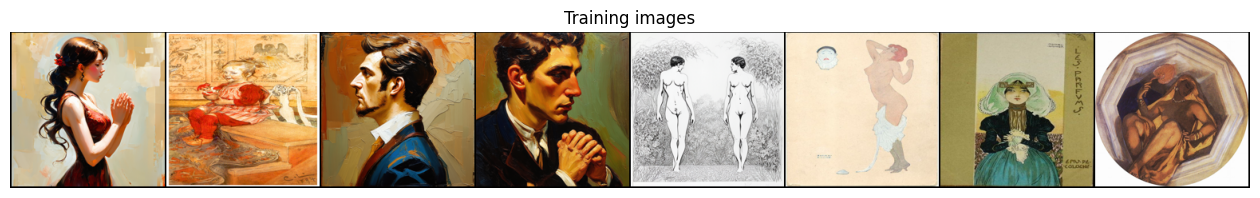

In [6]:
IMG_EXTS = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

def list_images(root):
    root = Path(root)
    if not root.is_dir():
        raise FileNotFoundError(f"DATA_ROOT does not exist: {root}")
    files = sorted(p for p in root.rglob("*") if p.suffix.lower() in IMG_EXTS)
    if not files:
        raise FileNotFoundError(f"No images found under {root}")
    return files

def caption_for(path):
    """Caption = sidecar .txt file next to the image if present, otherwise DEFAULT_CAPTION."""
    txt = path.with_suffix(".txt")
    if txt.exists():
        text = txt.read_text().strip()
        if text:
            return text
    return DEFAULT_CAPTION


class ImageCaptionDataset(torch.utils.data.Dataset):
    def __init__(
        self, 
        files, 
        resolution, 
        random_flip=True
    ) -> None:
        self.files = files
        tfms = [
            transforms.Resize(
                resolution, 
                interpolation=transforms.InterpolationMode.BILINEAR
            ),
            transforms.CenterCrop(resolution),
        ]
        if random_flip:
            tfms.append(transforms.RandomHorizontalFlip())
        tfms += [transforms.ToTensor(), transforms.Normalize([0.5], [0.5])]
        self.transform = transforms.Compose(tfms)

    def __len__(self):
        return len(self.files)

    def __getitem__(self, i):
        for offset in range(len(self.files)):          # skip unreadable files
            path = self.files[(i + offset) % len(self.files)]
            try:
                image = Image.open(path).convert("RGB")
                return {"pixel_values": self.transform(image), "caption": caption_for(path)}
            except Exception:
                continue
        raise RuntimeError("No readable images found")


def collate_fn(batch):
    return {
        "pixel_values": torch.stack([b["pixel_values"] for b in batch]),
        "captions": [b["caption"] for b in batch],
    }


files = list_images(DATA_ROOT)
dataset = ImageCaptionDataset(files, RESOLUTION, RANDOM_FLIP)
dataloader = torch.utils.data.DataLoader(
    dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS,
    collate_fn=collate_fn, drop_last=True,
)
print(f"{len(dataset)} images under {DATA_ROOT}")
print("Example caption:", caption_for(files[0]))

# Preview
preview = []
for p in random.sample(files, min(8, len(files))):
    try:
        preview.append(Image.open(p).convert("RGB").resize((192, 192)))
    except Exception:
        pass   # skip unreadable files in the preview (the dataset loader skips them too)

grid = vutils.make_grid(torch.stack([TF.to_tensor(im) for im in preview]), nrow=8, padding=2)
plt.figure(figsize=(16, 3)); plt.axis("off"); plt.title("Training images")
plt.imshow(grid.permute(1, 2, 0)); plt.show()

## <b><div class="alert alert-block alert-info" style='padding:15px;background-color:#37006f;color:white;border-radius:40px;font-size:110%;text-align: center;margin: auto;'>6 | Load Stable Diffusion</div></b>


Stable Diffusion is a *latent* diffusion model: a **VAE** compresses images into a small latent space, a **UNet** denoises in that space, and a **CLIP text encoder** provides the text conditioning. Only the UNet gets LoRA adapters here; the VAE and text encoder stay frozen.

In [ ]:
import os

# Set your Hugging Face token
os.environ["HF_TOKEN"] = "hf_xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx" # Replace with your actual token

In [7]:
tokenizer = CLIPTokenizer.from_pretrained(MODEL_ID, subfolder="tokenizer")
text_encoder = CLIPTextModel.from_pretrained(MODEL_ID, subfolder="text_encoder")
vae = AutoencoderKL.from_pretrained(MODEL_ID, subfolder="vae")
unet = UNet2DConditionModel.from_pretrained(MODEL_ID, subfolder="unet")
noise_scheduler = DDPMScheduler.from_pretrained(MODEL_ID, subfolder="scheduler")
print("prediction type:", noise_scheduler.config.prediction_type, "| train timesteps:", noise_scheduler.config.num_train_timesteps)

Loading weights: 100%|██████████| 196/196 [00:00<00:00, 759.44it/s]
d:\Personal Projects\picasso\.venv\lib\site-packages\huggingface_hub\utils\_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


prediction type: epsilon | train timesteps: 1000


In [8]:
# Freeze everything, move to the GPU in half precision, then add trainable LoRA layers to the UNet
vae.requires_grad_(False)
text_encoder.requires_grad_(False)
unet.requires_grad_(False)
vae.to(DEVICE, dtype=WEIGHT_DTYPE).eval()
text_encoder.to(DEVICE, dtype=WEIGHT_DTYPE).eval()
unet.to(DEVICE, dtype=WEIGHT_DTYPE)

if GRADIENT_CHECKPOINTING:
    unet.enable_gradient_checkpointing()

lora_config = LoraConfig(
    r=RANK,
    lora_alpha=RANK,
    init_lora_weights="gaussian",
    target_modules=["to_k", "to_q", "to_v", "to_out.0"],   # attention projections
)
unet.add_adapter(lora_config)
if WEIGHT_DTYPE == torch.float16:
    cast_training_params(unet, dtype=torch.float32)         # train the LoRA weights in fp32

lora_params = [p for p in unet.parameters() if p.requires_grad]
n_train = sum(p.numel() for p in lora_params)
n_total = sum(p.numel() for p in unet.parameters())
print(f"Trainable LoRA parameters: {n_train/1e6:.2f}M of {n_total/1e6:.1f}M UNet parameters ({100*n_train/n_total:.2f}%)")

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in UNet2DConditionModel that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


Trainable LoRA parameters: 3.19M of 862.7M UNet parameters (0.37%)


## <b><div class="alert alert-block alert-info" style='padding:15px;background-color:#37006f;color:white;border-radius:40px;font-size:110%;text-align: center;margin: auto;'>7 | Optimizer, schedule, loss, and helpers</div></b>

In [ ]:
optimizer = torch.optim.AdamW(
    lora_params, 
    lr=LEARNING_RATE, 
    betas=(0.9, 0.999), 
    weight_decay=1e-2, 
    eps=1e-8
)
lr_scheduler = get_scheduler(
    LR_SCHEDULER, 
    optimizer=optimizer, 
    num_warmup_steps=LR_WARMUP_STEPS, 
    num_training_steps=MAX_STEPS
)
scaler = torch.amp.GradScaler(DEVICE, enabled=USE_AMP)
alphas_cumprod = noise_scheduler.alphas_cumprod.to(DEVICE)


def autocast():
    return torch.autocast(
        device_type=DEVICE, 
        dtype=WEIGHT_DTYPE, 
        enabled=USE_AMP
    )


def compute_loss(
    pixel_values, 
    captions
):
    """
    One forward pass: image -> latents, add noise, predict it, weighted MSE.
    """
    with torch.no_grad():
        latents = vae.encode(
            pixel_values.to(DEVICE, dtype=WEIGHT_DTYPE)
        ).latent_dist.sample()
        latents = latents * vae.config.scaling_factor
        ids = tokenizer(captions, max_length=tokenizer.model_max_length, padding="max_length",
                        truncation=True, return_tensors="pt").input_ids.to(DEVICE)
        text_emb = text_encoder(ids)[0]

    noise = torch.randn_like(latents)
    t = torch.randint(0, noise_scheduler.config.num_train_timesteps, (latents.size(0),), device=DEVICE).long()
    noisy = noise_scheduler.add_noise(latents, noise, t)

    if noise_scheduler.config.prediction_type == "epsilon":
        target = noise
    elif noise_scheduler.config.prediction_type == "v_prediction":
        target = noise_scheduler.get_velocity(latents, noise, t)
    else:
        raise ValueError(noise_scheduler.config.prediction_type)

    with autocast():
        pred = unet(noisy, t, text_emb).sample

    loss = F.mse_loss(pred.float(), target.float(), reduction="none").mean(dim=(1, 2, 3))
    if SNR_GAMMA is not None:                              # min-SNR weighting
        snr = alphas_cumprod[t] / (1 - alphas_cumprod[t])
        weights = snr.clamp(max=SNR_GAMMA) / snr
        if noise_scheduler.config.prediction_type == "v_prediction":
            weights = snr.clamp(max=SNR_GAMMA) / (snr + 1)
        loss = loss * weights
    return loss.mean()


def infinite(dl):
    while True:
        for batch in dl:
            yield batch


# ---- sampling with the current UNet (LoRA included) ----
sample_pipe = StableDiffusionPipeline(
    vae=vae, text_encoder=text_encoder, tokenizer=tokenizer, unet=unet,
    scheduler=DPMSolverMultistepScheduler.from_config(noise_scheduler.config),
    safety_checker=None, feature_extractor=None, requires_safety_checker=False,
)
sample_pipe.set_progress_bar_config(disable=True)



In [ ]:
@torch.no_grad()
def generate(
    prompts, 
    seeds, 
    steps=25, 
    guidance=7.5, 
    lora_scale=1.0
) -> list[Image.Image]:
    was_training = unet.training
    unet.eval()
    images = []
    for prompt, seed in zip(prompts, seeds):
        gen = torch.Generator(device=DEVICE).manual_seed(seed)
        with autocast():
            out = sample_pipe(prompt, num_inference_steps=steps, guidance_scale=guidance, generator=gen,
                              height=RESOLUTION, width=RESOLUTION,
                              cross_attention_kwargs={"scale": lora_scale})
        images.append(out.images[0])
    unet.train(was_training)
    return images


def show_images(images, titles=None, size=4):
    fig, axes = plt.subplots(1, len(images), figsize=(size * len(images), size + 0.4))
    axes = np.atleast_1d(axes)
    for i, (ax, im) in enumerate(zip(axes, images)):
        ax.axis("off")
        ax.imshow(im)
        if titles:
            ax.set_title(titles[i], fontsize=8, wrap=True)
    plt.tight_layout(); plt.show()


# ---- saving ----
def save_lora(directory):
    """Writes pytorch_lora_weights.safetensors, loadable with pipe.load_lora_weights()."""
    state = convert_state_dict_to_diffusers(get_peft_model_state_dict(unet))
    StableDiffusionPipeline.save_lora_weights(
        save_directory=directory, 
        unet_lora_layers=state, 
        safe_serialization=True
    )


def save_training_state(path, step, losses):
    torch.save({
        "lora": get_peft_model_state_dict(unet),
        "optimizer": optimizer.state_dict(),
        "lr_scheduler": lr_scheduler.state_dict(),
        "scaler": scaler.state_dict(),
        "step": step,
        "losses": losses,
    }, path)


global_step, loss_history = 0, []
if RESUME_FROM and os.path.isfile(RESUME_FROM):
    state = torch.load(RESUME_FROM, map_location=DEVICE)
    set_peft_model_state_dict(unet, state["lora"])
    optimizer.load_state_dict(state["optimizer"])
    lr_scheduler.load_state_dict(state["lr_scheduler"])
    scaler.load_state_dict(state["scaler"])
    global_step, loss_history = state["step"], state["losses"]
    print(f"Resumed from step {global_step}")

## <b><div class="alert alert-block alert-info" style='padding:15px;background-color:#37006f;color:white;border-radius:40px;font-size:110%;text-align: center;margin: auto;'>8 | Baseline samples</div></b>

LoRA starts as a no-op, so these images come from the original Stable Diffusion model. We keep them (same prompts and seeds) to compare after training.

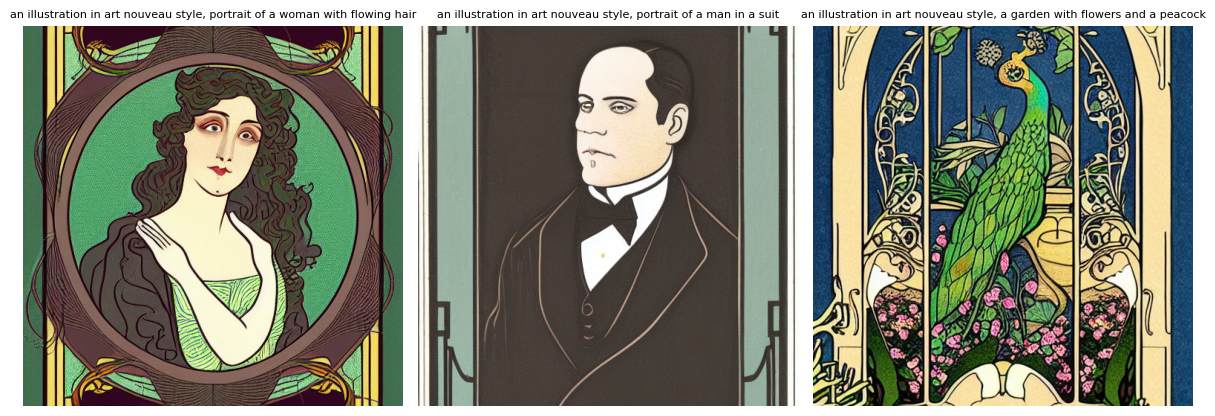

In [10]:
baseline_images = generate(VALIDATION_PROMPTS, VALIDATION_SEEDS) if global_step == 0 else None
if baseline_images:
    show_images(baseline_images, VALIDATION_PROMPTS)

## <b><div class="alert alert-block alert-info" style='padding:15px;background-color:#37006f;color:white;border-radius:40px;font-size:110%;text-align: center;margin: auto;'>9 | Train</div></b>

Each optimizer step accumulates `GRAD_ACCUM` micro-batches. Every `VALIDATION_EVERY` steps the notebook generates the validation images; every `CHECKPOINT_EVERY` steps it saves the LoRA weights and a resumable training state. Stopping the cell (interrupt) still saves.


In [ ]:
data_iter = infinite(dataloader)
unet.train()
pbar = tqdm(total=MAX_STEPS, initial=global_step, desc="Fine-tuning")

try:
    while global_step < MAX_STEPS:
        step_loss = 0.0
        for _ in range(GRAD_ACCUM):
            batch = next(data_iter)
            loss = compute_loss(batch["pixel_values"], batch["captions"]) / GRAD_ACCUM
            if not torch.isfinite(loss):
                raise RuntimeError("Non-finite loss; try a lower LEARNING_RATE.")
            scaler.scale(loss).backward()
            step_loss += loss.item()

        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(lora_params, MAX_GRAD_NORM)
        scaler.step(optimizer)
        scaler.update()
        lr_scheduler.step()
        optimizer.zero_grad(set_to_none=True)

        global_step += 1
        loss_history.append(step_loss)
        pbar.update(1)
        pbar.set_postfix(loss=f"{np.mean(loss_history[-50:]):.4f}", lr=f"{lr_scheduler.get_last_lr()[0]:.1e}")

        if global_step % VALIDATION_EVERY == 0 or global_step == MAX_STEPS:
            show_images(generate(VALIDATION_PROMPTS, VALIDATION_SEEDS), [f"step {global_step}"] * len(VALIDATION_PROMPTS), size=3)
        if global_step % CHECKPOINT_EVERY == 0:
            save_lora(OUTPUT_DIR)
            save_training_state(os.path.join(OUTPUT_DIR, "training_state.pt"), global_step, loss_history)
except KeyboardInterrupt:
    print("Interrupted; saving what we have.")
finally:
    pbar.close()
    save_lora(OUTPUT_DIR)
    save_training_state(os.path.join(OUTPUT_DIR, "training_state.pt"), global_step, loss_history)
    print(f"Saved LoRA weights to {OUTPUT_DIR}/ at step {global_step}")

## Training loss

In [ ]:
losses = np.array(loss_history)
window = min(50, max(1, len(losses)))
plt.figure(figsize=(10, 4))
plt.plot(losses, alpha=0.3, label="loss per step")
if len(losses) >= window:
    plt.plot(range(window - 1, len(losses)), np.convolve(losses, np.ones(window) / window, mode="valid"), label=f"moving average ({window})")
plt.xlabel("optimizer step"); plt.ylabel("loss"); plt.legend(); plt.show()

## Before vs. after

Same prompts, same seeds. Top row: original Stable Diffusion. Bottom row: after fine-tuning.

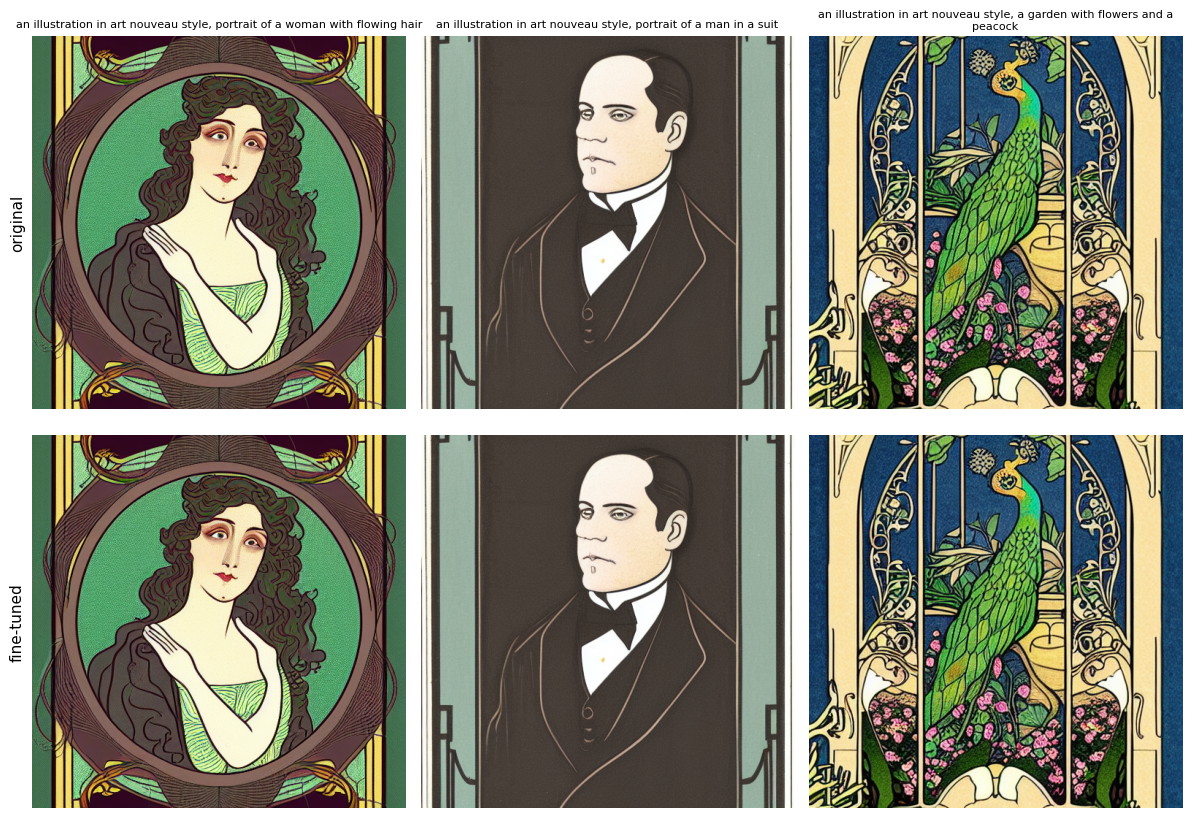

: 

In [ ]:
after_images = generate(VALIDATION_PROMPTS, VALIDATION_SEEDS)
rows = ([baseline_images] if baseline_images else []) + [after_images]
fig, axes = plt.subplots(len(rows), len(after_images), figsize=(4 * len(after_images), 4.2 * len(rows)))
axes = np.array(axes).reshape(len(rows), len(after_images))
for r, imgs in enumerate(rows):
    for c, im in enumerate(imgs):
        axes[r, c].axis("off"); axes[r, c].imshow(im)
        if r == 0:
            axes[r, c].set_title(VALIDATION_PROMPTS[c], fontsize=8, wrap=True)
    axes[r, 0].text(-0.02, 0.5, "original" if (baseline_images and r == 0) else "fine-tuned", transform=axes[r, 0].transAxes,
                    rotation=90, va="center", ha="right", fontsize=11)
plt.tight_layout(); plt.show()

## Use the saved LoRA for inference

This reloads a fresh copy of the base model and applies only the saved LoRA file, which is how you would use it later (in another notebook, or share just the small file). The LoRA *scale* blends between the original model (0) and the full fine-tune (1); values above 1 exaggerate the style.

In [ ]:
pipe = StableDiffusionPipeline.from_pretrained(MODEL_ID, torch_dtype=WEIGHT_DTYPE, safety_checker=None).to(DEVICE)
pipe.load_lora_weights(OUTPUT_DIR)
pipe.set_progress_bar_config(disable=True)

In [13]:
prompt = "an illustration in art nouveau style, a cat in a forest with flowers and butterflies"
scales = [0.0, 0.5, 1.0, 1.3]
images = []
for s in scales:
    gen = torch.Generator(device=DEVICE).manual_seed(7)
    images.append(pipe(prompt, num_inference_steps=30, guidance_scale=7.5, generator=gen,
                       height=RESOLUTION, width=RESOLUTION, cross_attention_kwargs={"scale": s}).images[0])

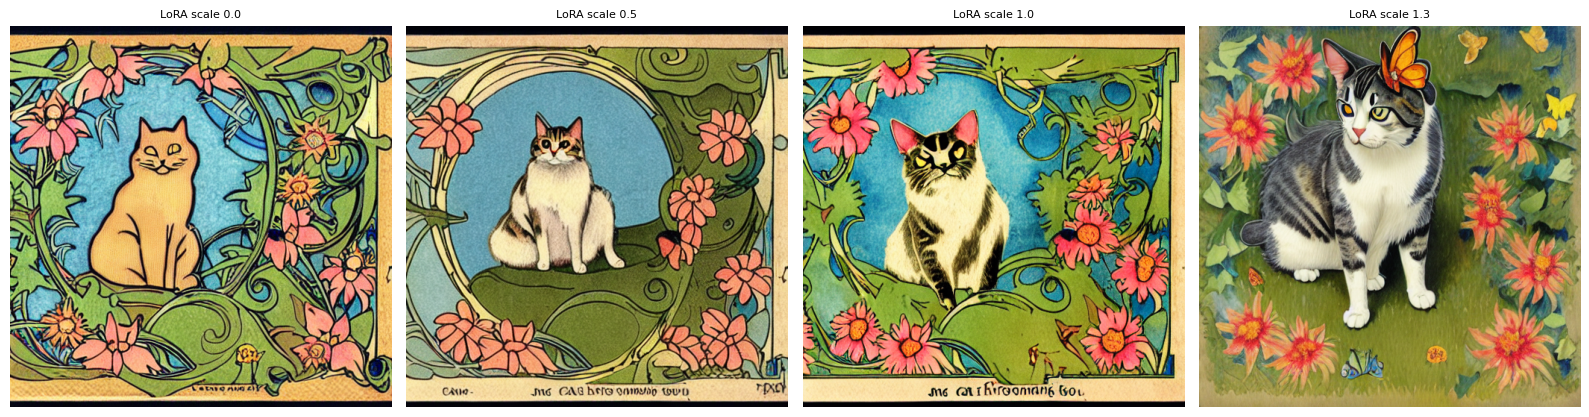

In [14]:
show_images(images, [f"LoRA scale {s}" for s in scales])

## Download the result

`lora_output/pytorch_lora_weights.safetensors` is the fine-tuned model (the base model is not included; it is downloaded from the Hub when you load it). Zip and download it:

In [ ]:
import shutil
print(os.listdir(OUTPUT_DIR))
size_mb = os.path.getsize(os.path.join(OUTPUT_DIR, "pytorch_lora_weights.safetensors")) / 1e6
print(f"LoRA file size: {size_mb:.1f} MB")
shutil.make_archive("lora_output", "zip", OUTPUT_DIR)
print("Wrote lora_output.zip (download it from the file browser / Output panel)")